# Supplemental Figure 5, Panel D

Barplots showing log2FC motif enrichment for NR3C1 (GR) and STAT1 and cREs that gain accessibility due to Dex or IFNg stimulus at 1h.
Motif enrichments calculated in:
- NR3C1_Dex_enr.ipynb (NR3C1 enrichment in 1h Dex cREs)
- NR3C1_IFN_enr.ipynb (NR3C1 enrichment in 1h IFNg cREs)
- STAT1_Dex_enr.ipynb (STAT1 enrichment in 1h Dex cREs)
- STAT1_IFN_enr.ipynb (STAT1 enrichment in 1h IFNg cREs)


*Output: PanelD.pdf*

# Setup

In [1]:
#load packages
library(tidyverse)
library(here)
here::i_am("figures/SuppFig5/PanelD/PanelD.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig5/PanelD

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
 [5] dplyr_1.1.4     purrr_1.0.2     readr_2.1.5     tidyr_1.3.1    
 [9] tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    base64enc_0.1-3   

# Load data

In [2]:
stat1_ifn <- read.delim("STAT1_enr_IFN-up-1h.tsv")
stat1_dex <- read.delim("STAT1_enr_Dex-up-1h.tsv")
nr3c1_ifn <- read.delim("NR3C1_enr_IFN-up-1h.tsv")
nr3c1_dex <- read.delim("NR3C1_enr_Dex-up-1h.tsv")

# Generate plot

Saving 2 x 7 in image


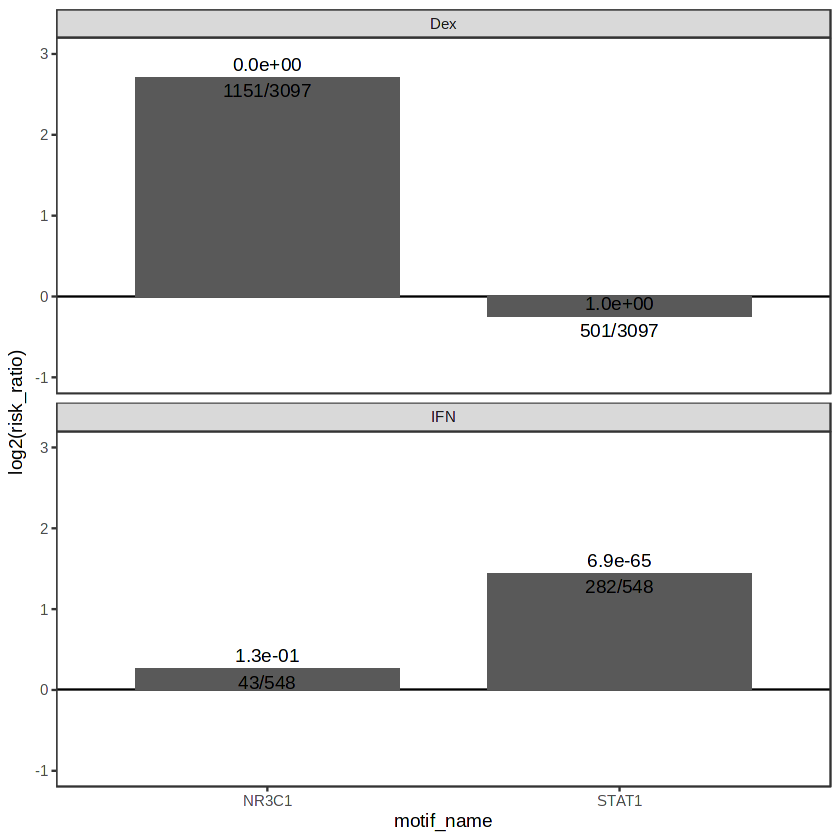

In [3]:
all <- rbind(nr3c1_dex, stat1_dex, nr3c1_ifn, stat1_ifn) %>% mutate(treatment=c("Dex", "Dex", "IFN", "IFN"))

all %>% 
    ggplot(aes(x=motif_name, y=log2(risk_ratio))) + 
    facet_wrap(~treatment, scales="free_y", ncol=1) +
    ylim(-1,3) + 
    geom_hline(yintercept=0) + 
        geom_col(width=.75) +
        geom_text(aes(label=paste0(format(p, digits=2), "\n", fg_motif_pos, "/", n_foreground)))

ggsave("PanelD.pdf", width=2)